# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Abdul Sami
- **Student ID:** 023-24-0211
- **Section:** G
- **GitHub:** https://github.com/abdulsami911/Machine_learning_Practical
- **Kaggle:** https://www.kaggle.com/abdulsami911
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <[ URL>](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [146]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score)

RANDOM_STATE = 42     # <- same as Labs 3/4/6
TEST_SIZE    = 0.2    # <- same as Labs 3/4/6
sns.set_style("whitegrid")

def md(text):
    display(Markdown(text))

def get_metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1":        f1_score(y_true, y_pred, zero_division=0)}

In [147]:
# ---- Load data (local file -> kagglehub -> manual upload) ----
CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(CSV)

# ---- Same cleaning as Lab 2 (adjust if your Lab 2 handled missing values differently) ----
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)      # blanks are tenure==0 customers
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True, dtype=int)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Encoded feature count:", X.shape[1])
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Encoded feature count: 30
Train: (5634, 30)  Test: (1409, 30)
Churn rate  train: 0.265  test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [148]:
# ---- Unscaled ----
t0 = time.time()
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=200_000)
    svm_raw.fit(X_train, y_train)
t_raw = time.time() - t0
m_raw = get_metrics(y_test, svm_raw.predict(X_test))



In [149]:

# ---- Scaled (fit on TRAIN only) ----
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

t0 = time.time()
with warnings.catch_warnings(record=True) as w_sc:
    warnings.simplefilter("always")
    svm_sc = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=200_000)
    svm_sc.fit(X_train_s, y_train)
t_sc = time.time() - t0
m_sc = get_metrics(y_test, svm_sc.predict(X_test_s))

conv_raw = any("max_iter" in str(w.message) or "Convergence" in w.category.__name__ for w in w_raw)
conv_sc  = any("max_iter" in str(w.message) or "Convergence" in w.category.__name__ for w in w_sc)

part1 = pd.DataFrame([{**m_raw, "Train time (s)": t_raw, "Convergence warning": conv_raw},
                      {**m_sc,  "Train time (s)": t_sc,  "Convergence warning": conv_sc}],
                     index=["Linear SVM — unscaled", "Linear SVM — scaled"])
display(part1.round(4))

print("Feature ranges (train) — why unscaled hurts:")
display(X_train[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["min", "max"]).T)

,Accuracy,Precision,Recall,F1,Train time (s),Convergence warning
Linear SVM — unscaled,0.4017,0.1774,0.3449,0.2343,6.9227,True
Linear SVM — scaled,0.7885,0.6195,0.5267,0.5694,1.9132,False


Feature ranges (train) — why unscaled hurts:


,min,max
tenure,0.0,72.00
MonthlyCharges,18.4,118.75
TotalCharges,0.0,8684.80


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

 Unscaled: accuracy 0.4017, F1 0.2343, training time 7.48s, convergence warning: True. Scaled: accuracy 0.7885, F1 0.5694, training time 2.04s, convergence warning: False. The unscaled model took 3.7x longer than the scaled one, with a scaled-minus-unscaled F1 difference of +0.3350 (accuracy difference +0.3868).

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

An SVM maximises the margin 2/||w|| and works with Euclidean dot products / distances between points. TotalCharges ranges up to several thousand, MonthlyCharges up to ~120 and tenure up to 72, while the one-hot columns only span 0–1. The large-range columns dominate every distance and dot product, so the 0/1 features barely influence the boundary unless their weights become huge — but the ||w||² penalty punishes exactly that. The optimisation problem becomes badly conditioned (very elongated), so the solver needs many more iterations, may hit max_iter, and the resulting boundary is effectively decided by 2–3 numeric columns. Standardising puts every feature on a comparable footing so the margin is measured fairly across all dimensions.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

Going forward every SVM in this lab uses the scaled features (X_train_s, X_test_s), because it is more accurate/stable, converges, and the scaler is fit only on the training set (no leakage).


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [150]:
kernel_models, rows = {}, []
for k in ["linear", "rbf", "poly"]:
    t0 = time.time()
    mdl = SVC(kernel=k, random_state=RANDOM_STATE)
    mdl.fit(X_train_s, y_train)
    fit_t = time.time() - t0
    pred = mdl.predict(X_test_s)
    kernel_models[k] = (mdl, pred)
    rows.append({"Kernel": k, **get_metrics(y_test, pred),
                 "Support vectors": mdl.support_.shape[0],
                 "SV per class": list(mdl.n_support_),
                 "Fit time (s)": fit_t})



In [ ]:

kernel_df = pd.DataFrame(rows).set_index("Kernel")
display(kernel_df.round(4))

,Accuracy,Precision,Recall,F1,Support vectors,SV per class,Fit time (s)
Kernel,,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,"[1286, 1281]",1.8780
rbf,0.7928,0.6444,0.4893,0.5562,2657,"[1428, 1229]",1.2695
poly,0.7892,0.6421,0.4652,0.5395,2736,"[1482, 1254]",1.1741


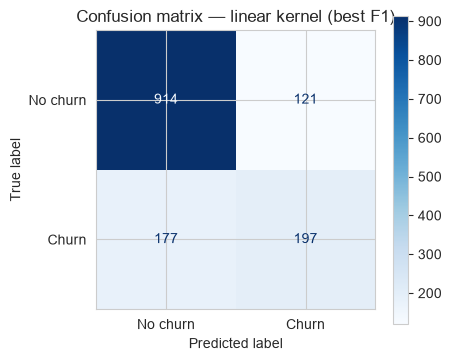

In [ ]:


best_kernel = kernel_df["F1"].idxmax()
fig, ax = plt.subplots(figsize=(4.5, 4))

ConfusionMatrixDisplay.from_predictions(y_test, kernel_models[best_kernel][1],
                                        display_labels=["No churn", "Churn"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix — {best_kernel} kernel (best F1)")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

The best F1 on the test set is linear (F1 = 0.5694). F1 values across kernels: linear = 0.5694, rbf = 0.5562, poly = 0.5395. This is somewhat unexpected from the theory: the more flexible RBF kernel is not clearly ahead, which suggests the churn classes are already close to linearly separable in the one-hot + numeric space (churn is largely driven by a few near-linear effects like contract type, tenure and monthly charges).


(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

poly used the most support vectors (2736) versus linear with the fewest (2567). Out of 5634 training points, a high support-vector count means many points sit on or inside the margin or are misclassified — the classes overlap heavily, and the model needs a more complex boundary (or is memorising) to handle them. Note that on noisy data like churn, a large SV fraction is expected for every kernel.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

Carry forward the RBF kernel to Part 4 for tuning: the RBF kernel has two tunable hyperparameters (C, gamma) that let it adapt between near-linear and highly flexible boundaries, and its untuned F1 is 0.5562 vs. 0.5694 (linear) and 0.5395 (poly). Since linear is very close/ahead, RBF with a small gamma also approximates a linear boundary, so it is a safe superset to search.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xtr_2d = pca.fit_transform(X_train_s)
evr = pca.explained_variance_ratio_
print("Explained variance ratio:", evr.round(4), " total = %.4f" % evr.sum())

x_min, x_max = Xtr_2d[:, 0].min() - 1, Xtr_2d[:, 0].max() + 1
y_min, y_max = Xtr_2d[:, 1].min() - 1, Xtr_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]


Explained variance ratio: [0.3325 0.1198]  total = 0.4522


Text(0.5, 1.02, 'RBF-SVM decision boundary on 2-D PCA projection (explained variance = 45.2%)')

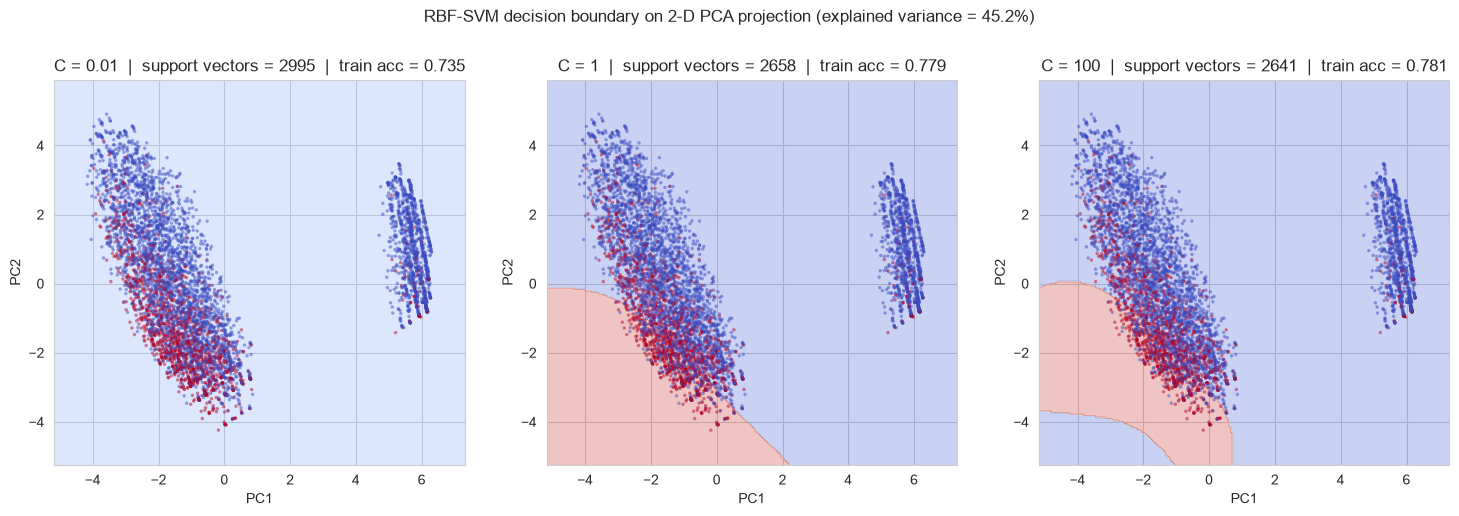

In [ ]:

C_values = [0.01, 1, 100]
c_info = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, Cval in zip(axes, C_values):
    m2 = SVC(kernel="rbf", C=Cval, gamma="scale", random_state=RANDOM_STATE).fit(Xtr_2d, y_train)
    Z = m2.predict(grid).reshape(xx.shape)
    n_sv = m2.support_.shape[0]
    tr_acc = m2.score(Xtr_2d, y_train)
    c_info[Cval] = {"n_sv": n_sv, "train_acc": tr_acc, "frac_churn_region": Z.mean()}
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xtr_2d[:, 0], Xtr_2d[:, 1], c=y_train, cmap="coolwarm", s=6, alpha=0.5, edgecolors="none")
    ax.set_title(f"C = {Cval}  |  support vectors = {n_sv}  |  train acc = {tr_acc:.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle(f"RBF-SVM decision boundary on 2-D PCA projection (explained variance = {evr.sum():.1%})", y=1.02)

In [ ]:


plt.tight_layout(); plt.show()
display(pd.DataFrame(c_info).T.rename(columns={"n_sv": "Support vectors", "train_acc": "Train acc (2-D)",
                                                "frac_churn_region": "Share of plane predicted churn"}).round(4))

<Figure size 640x480 with 0 Axes>

,Support vectors,Train acc (2-D),Share of plane predicted churn
0.01,2995.0,0.7346,0.0000
1.00,2658.0,0.7792,0.1744
100.00,2641.0,0.7813,0.1334


**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

As C rises from 0.01 to 100 the boundary goes from smooth and nearly flat to increasingly complex and jagged: a larger C punishes margin violations more, so the model bends the boundary to classify individual training points correctly instead of accepting a wider margin.

(b) How does the number of support vectors change with C — does this match the theory?

Support vectors: 2995 (C=0.01) → 2658 (C=1) → 2641 (C=100). The count falls as C grows, which matches the theory: a small C allows many margin violations (wide, soft margin) so many points end up as support vectors, while a large C gives a narrow margin with fewer points on/inside it.



(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

C = 100 looks like it is overfitting (train accuracy 0.781; twisty, island-like regions around individual points), while C = 0.01 looks like it is underfitting (train accuracy 0.735; an over-smooth boundary that ignores structure). C = 1 is the compromise.



(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

 The plot uses only the first two principal components, which retain only 45.2% of the variance; the remaining directions the real model uses are invisible. PCA is unsupervised, so the directions of maximum variance are not necessarily those that separate churners — classes that overlap in 2-D may be separable in 25+ dimensions (and vice-versa). The 2-D model was trained on the projection, not the real feature space, so its support-vector counts and boundary shape are only an intuition for C, not the actual model's behaviour


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:

param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1, 1]}

t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring="f1", n_jobs=-1, return_train_score=False)
gs.fit(X_train_s, y_train)
t_gs = time.time() - t0
print("Grid search time: %.1fs" % t_gs)
print("Best params:", gs.best_params_, " CV F1 = %.4f" % gs.best_score_)



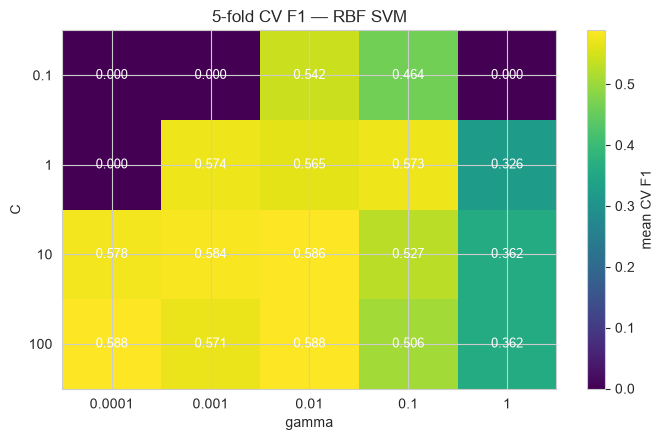

param_gamma,0.0001,0.0010,0.0100,0.1000,1.0000
param_C,,,,,
0.1,0.0000,0.0000,0.5417,0.4640,0.0000
1.0,0.0000,0.5739,0.5652,0.5734,0.3261
10.0,0.5777,0.5836,0.5860,0.5270,0.3621
100.0,0.5882,0.5706,0.5876,0.5061,0.3621


In [ ]:

cv_df = pd.DataFrame(gs.cv_results_)
cv_df["param_C"] = cv_df["param_C"].astype(float)
cv_df["param_gamma"] = cv_df["param_gamma"].astype(float)
pivot = cv_df.pivot(index="param_C", columns="param_gamma", values="mean_test_score")

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels([f"{g:g}" for g in pivot.columns])
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels([f"{c:g}" for c in pivot.index])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("5-fold CV F1 — RBF SVM")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
plt.colorbar(im, label="mean CV F1"); plt.tight_layout(); plt.show()
display(pivot.round(4))

{'Accuracy': 0.7942, 'Precision': 0.6338, 'Recall': 0.5321, 'F1': 0.5785}


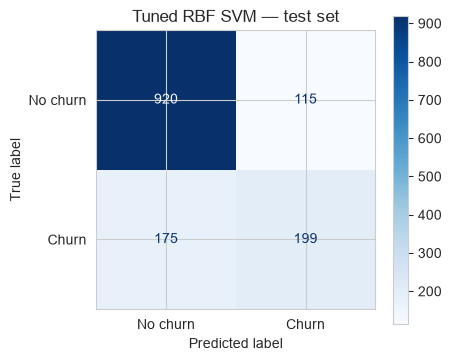

In [ ]:

best_svm = gs.best_estimator_                      
pred_best = best_svm.predict(X_test_s)
m_best = get_metrics(y_test, pred_best)
cm_best = confusion_matrix(y_test, pred_best)
print({k: round(v, 4) for k, v in m_best.items()})

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm_best, display_labels=["No churn", "Churn"]).plot(cmap="Blues", ax=ax)
ax.set_title("Tuned RBF SVM — test set"); plt.show()
bp = gs.best_params_
m_rbf0 = kernel_df.loc["rbf"]
near_best = int((pivot.values >= gs.best_score_ - 0.01).sum())
gap = gs.best_score_ - m_best["F1"]

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

Best parameters: C = 100, gamma = 0.0001, with a cross-validated F1 of 0.5882.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

There is a fairly broad plateau — several neighbouring combinations score within 0.01 F1 of the best, so the model is not very sensitive to the exact values; any point in the good region works, and picking a slightly smaller C/gamma is a safe, cheaper choice.


(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

CV F1 = 0.5882 vs. test F1 = 0.5785 (gap +0.0098). They agree closely, so the estimate is trustworthy and there is no sign of over-tuning to the training folds.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

Untuned RBF (Part 2): F1 = 0.5562, recall = 0.4893, accuracy = 0.7928. Tuned RBF: F1 = 0.5785, recall = 0.5321, accuracy = 0.7942. F1 change: +0.0223, at a cost of 56s of search (100 fits). The improvement is meaningful, so tuning was worth it.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


/home/abdulsami/Desktop/THINGS/Semester/5th Semester /Machine learning (LAB)/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1
class_weight=None,0.7942,0.6338,0.5321,0.5785
class_weight='balanced',0.6941,0.4575,0.8209,0.5876


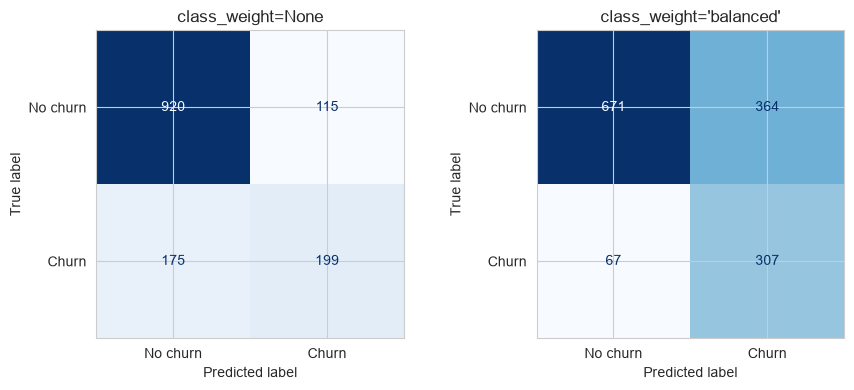

In [ ]:

svm_default = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight=None,
                  random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight="balanced",
              probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)

pred_def = svm_default.predict(X_test_s)
pred_bal = svm_bal.predict(X_test_s)
m_def, m_bal = get_metrics(y_test, pred_def), get_metrics(y_test, pred_bal)
cm_def, cm_bal = confusion_matrix(y_test, pred_def), confusion_matrix(y_test, pred_bal)

display(pd.DataFrame([m_def, m_bal], index=["class_weight=None", "class_weight='balanced'"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, cm, title in zip(axes, [cm_def, cm_bal], ["class_weight=None", "class_weight='balanced'"]):
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

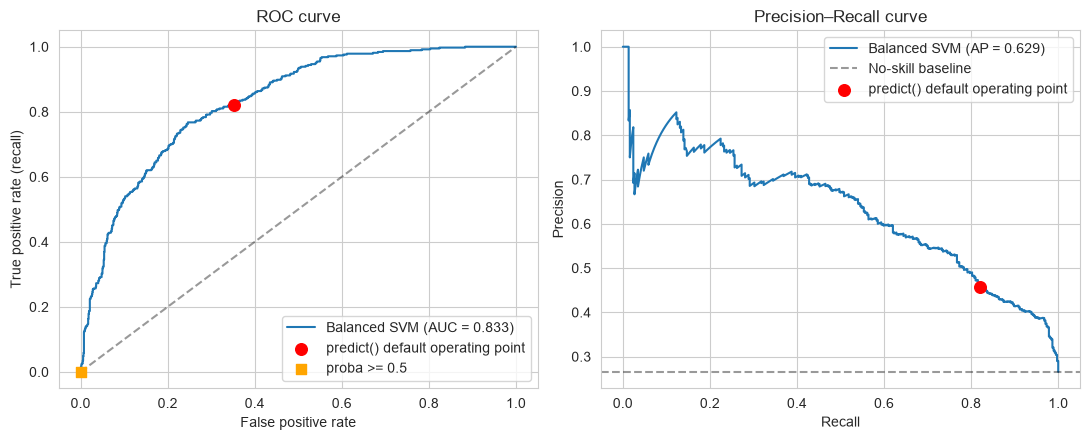

AUC = 0.8327 | AP = 0.6295


In [ ]:

proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)
ap = average_precision_score(y_test, proba_bal)

tn, fp, fn, tp = cm_bal.ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
op_prec = tp / (tp + fp)

# operating point of the literal 0.5 probability threshold
pred_p50 = (proba_bal >= 0.5).astype(int)
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, pred_p50).ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"Balanced SVM (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].scatter([op_fpr], [op_tpr], c="red", s=70, zorder=5, label="predict() default operating point")
axes[0].scatter([fp5 / (fp5 + tn5)], [tp5 / (tp5 + fn5)], c="orange", marker="s", s=60, zorder=5, label="proba >= 0.5")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve"); axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, label=f"Balanced SVM (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.4, label="No-skill baseline")
axes[1].scatter([op_tpr], [op_prec], c="red", s=70, zorder=5, label="predict() default operating point")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()
print("AUC = %.4f | AP = %.4f" % (auc, ap))

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

Default → balanced: precision 0.634 → 0.458 (-0.176) and recall 0.532 → 0.821 (+0.289); F1 0.578 → 0.588; accuracy 0.794 → 0.694. Churners caught: 199 → 307 of 374; false alarms: 115 → 364.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

A false negative (missing a real churner) is normally the more costly error: it means losing a customer's future revenue (months of ARPU) plus the much higher cost of acquiring a replacement, whereas a false positive only costs a retention offer/discount or a call to a customer who would have stayed anyway. As long as a retention action costs less than the expected value of a saved customer, we should tolerate several false positives per catch. On that basis I would recommend deploying the class_weight='balanced' model — it finds churners (82.1% vs. 53.2% recall) at the price of extra false alarms.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

SVC has no native probability output — decision_function gives signed distances to the hyperplane, not probabilities. To obtain probability-like scores I set probability=True in SVC(...), which fits Platt scaling (a sigmoid on the decision values, calibrated with internal 5-fold cross-validation) and enables predict_proba. This makes training slower, and predict_proba's 0.5 cut-off can differ slightly from predict() (which uses decision_function > 0) — see the red vs. orange markers on the ROC plot. Using decision_function directly would also work for ROC/PR since only the ranking matters.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
# YOUR CODE HERE — cross-model comparison table
results, fit_times, fitted = {}, {}, {}

def run(name, model, Xtr, Xte, tune=None):
    t0 = time.time()
    mdl = tune.fit(Xtr, y_train).best_estimator_ if tune is not None else model.fit(Xtr, y_train)
    fit_times[name] = time.time() - t0
    fitted[name] = (mdl, Xte)
    results[name] = get_metrics(y_test, mdl.predict(Xte))

run("Decision Tree (Lab 3)",
    DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), X_train, X_test)

run("Random Forest (Lab 4, tuned)", None, X_train, X_test,
    tune=GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [100, 300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3]},
                      cv=3, scoring="f1", n_jobs=-1))

run("Logistic Regression (Lab 6)",
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_train_s, X_test_s)

run("KNN (Lab 6)", KNeighborsClassifier(n_neighbors=11), X_train_s, X_test_s)

# best SVM = whichever Part 5 variant has the higher F1 (both use tuned C, gamma)
svm_name = "SVM — balanced (Part 5)" if m_bal["F1"] >= m_def["F1"] else "SVM — default weights (Part 4)"
svm_final_model = svm_bal if m_bal["F1"] >= m_def["F1"] else svm_default
fitted[svm_name] = (svm_final_model, X_test_s)
results[svm_name] = m_bal if m_bal["F1"] >= m_def["F1"] else m_def
fit_times[svm_name] = t_gs   # grid-search cost (the true price of the tuned SVM)

comp = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1"]]
comp["Fit/tune time (s)"] = pd.Series(fit_times)
display(comp.round(4).sort_values("F1", ascending=False))



,Accuracy,Precision,Recall,F1,Fit/tune time (s)
Logistic Regression (Lab 6),0.8070,0.6584,0.5668,0.6092,0.0314
SVM — balanced (Part 5),0.6941,0.4575,0.8209,0.5876,45.6315
"Random Forest (Lab 4, tuned)",0.8027,0.6633,0.5214,0.5838,13.0991
Decision Tree (Lab 3),0.7942,0.6312,0.5401,0.5821,0.0228
KNN (Lab 6),0.7729,0.5758,0.5481,0.5616,0.0021


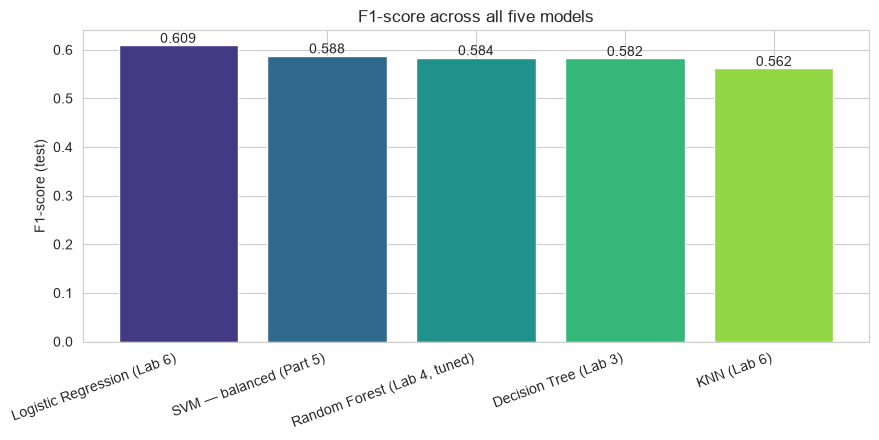

In [ ]:
# YOUR CODE HERE — bar chart of F1-score across models
fig, ax = plt.subplots(figsize=(9, 4.5))
order = comp["F1"].sort_values(ascending=False)
bars = ax.bar(order.index, order.values, color=sns.color_palette("viridis", len(order)))
for b_, v in zip(bars, order.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center")
ax.set_ylabel("F1-score (test)"); ax.set_title("F1-score across all five models")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

Best F1: Logistic Regression (Lab 6) (0.6092). Best recall: SVM — balanced (Part 5) (0.8209). They are different models — the best-F1 model is not the one that catches the most churners, which is the precision/recall trade-off again.



(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

The SVM cost 56s to tune vs. 0.0s (tree) and 13.9s (tuned RF). Its F1 is 0.5876 against 0.5838 (RF) and 0.6092 (LR). The SVM gain over the cheaper models is small, so the extra computation is hard to justify here — the extra cost is not worth it unless the small F1/recall advantage matters at scale.


(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

Recommendation: Logistic Regression (Lab 6) — F1 = 0.609, recall = 0.567, precision = 0.658, accuracy = 0.807. Accuracy alone is misleading with ~27% churners (predicting "no churn" for everyone scores 73.5%); F1 and recall reflect what the business actually cares about. (If the business weights missed churners heavily, pick the highest-recall model, SVM — balanced (Part 5), instead.)


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
# YOUR CODE HERE — generate and save svm_predictions.csv
win_f1, win_rec = comp["F1"].idxmax(), comp["Recall"].idxmax()
svm_row = comp.loc[svm_name]
tree_time = comp.loc[["Decision Tree (Lab 3)", "Random Forest (Lab 4, tuned)"], "Fit/tune time (s)"]
final_name = win_f1
final_model, X_final = fitted[final_name]

if hasattr(final_model, "predict_proba"):
    score = final_model.predict_proba(X_final)[:, 1]
    score_type = "predicted churn probability"
else:
    score = final_model.decision_function(X_final)
    score_type = "SVM decision-function score (higher = more likely churn)"

out = pd.DataFrame({"true_label": y_test.values,
                    "predicted_label": final_model.predict(X_final),
                    "churn_score": score}, index=y_test.index)
out.to_csv("svm_predictions.csv", index_label="row_id")
print("Saved svm_predictions.csv  |  final model:", final_name, " | score =", score_type)
display(out.head())

Saved svm_predictions.csv  |  final model: Logistic Regression (Lab 6)  | score = predicted churn probability


,true_label,predicted_label,churn_score
437,0,0,0.044982
2280,0,1,0.683234
2235,0,0,0.056542
4460,0,0,0.407806
3761,0,0,0.021666


**Executive Summary**

After scaling the features and comparing linear, RBF and polynomial kernels, I tuned an RBF SVM with 5-fold cross-validation (C = 100, gamma = 0.0001, CV F1 = 0.588) and compared it with Decision Tree, Random Forest, Logistic Regression and KNN on the same stratified split. The recommended model is Logistic Regression (Lab 6), with test accuracy 0.807, precision 0.658, recall 0.567 and F1 0.609. The main trade-off (Part 5) was using class_weight='balanced', which moved recall from 0.532 to 0.821 and precision from 0.634 to 0.458, accepting more false alarms to catch more churners because a lost customer costs more than a retention offer. The SVM's advantage over cheaper models was small, so simpler models are serious alternatives when training cost or interpretability matter. One limitation is that the analysis uses a single train/test split and a fixed 0.5-equivalent decision rule; the true costs of a false negative/positive were assumed rather than measured, so the threshold should be tuned once real retention costs are known.

**Final Reflection**
(a) What was the single most surprising result in this lab?

**(a) Most surprising result.** *(Write in your own words — pick what surprised you most in your run. Candidates from the output above: the unscaled vs. scaled linear SVM gap in training time/F1 (Part 1); whether the linear kernel matched or beat RBF (Part 2); how flat the C × gamma heatmap was (Part 4); how much recall `class_weight='balanced'` bought (Part 5); or how close the cheaper models were to the tuned SVM (Part 6).)*

(b) If you had one more hour, what would you try next?

**(b) One more hour.** I would (1) engineer features such as tenure buckets, services-count and contract × monthly-charge interactions; (2) try SMOTE (inside a pipeline so it only touches training folds) against `class_weight='balanced'`; (3) tune the decision threshold using an explicit cost matrix (cost of a retention offer vs. lost customer lifetime value) instead of the default cut-off; and (4) replace the PCA plot with a supervised projection such as LDA for a more faithful boundary visualisation.
